# Calories Burnt, Regression (Fitbit daily activity)

Predict how many calories a person burns in a day from their Fitbit activity. The data is real: the crowd-sourced Fitbit dataset from Furberg et al. (RTI International, Zenodo record 53894, CC BY 4.0), where 33 Amazon Mechanical Turk respondents shared their Fitbit exports for April 12 to May 12, 2016. It's the same data as the popular Kaggle "FitBit Fitness Tracker Data". I use `dailyActivity_merged.csv`: 940 person-days with steps, distance, minutes at each activity level, and Fitbit's own calorie estimate.

Two things to know up front. The target is Fitbit's *estimate* of calories (it uses the person's profile and heart rate when available), not a lab measurement. And Fitbit's daily total includes resting metabolism, which depends on body size, age and sex, none of which are in this file. So a big part of the target is a per-person baseline the features can't see.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(123)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA_DIR = Path("../../data/calories_burnt"); DATA_DIR.mkdir(parents=True, exist_ok=True)


## Load the Fitbit daily activity file

I drop days with zero steps and zero calories, which are days the tracker wasn't worn or synced.

In [2]:
import io, urllib.request, zipfile
CSV = DATA_DIR / "dailyActivity_merged.csv"
if not CSV.exists():
    url = "https://zenodo.org/api/records/53894/files/mturkfitbit_export_4.12.16-5.12.16.zip/content"
    zf = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    name = [n for n in zf.namelist() if n.endswith("dailyActivity_merged.csv")][0]
    CSV.write_bytes(zf.read(name))

raw = pd.read_csv(CSV)
df = raw[(raw["TotalSteps"] > 0) & (raw["Calories"] > 0)].copy()
df = df.rename(columns={"Calories": "calories"})
print("raw:", raw.shape, "| kept:", df.shape, "| people:", df["Id"].nunique())
df[["Id", "ActivityDate", "TotalSteps", "VeryActiveMinutes", "SedentaryMinutes", "calories"]].head()

raw: (940, 15) | kept: (863, 15) | people: 33


,Id,ActivityDate,TotalSteps,VeryActiveMinutes,SedentaryMinutes,calories
0,1503960366,4/12/2016,13162,25,728,1985
1,1503960366,4/13/2016,10735,21,776,1797
2,1503960366,4/14/2016,10460,30,1218,1776
3,1503960366,4/15/2016,9762,29,726,1745
4,1503960366,4/16/2016,12669,36,773,1863


## quick look

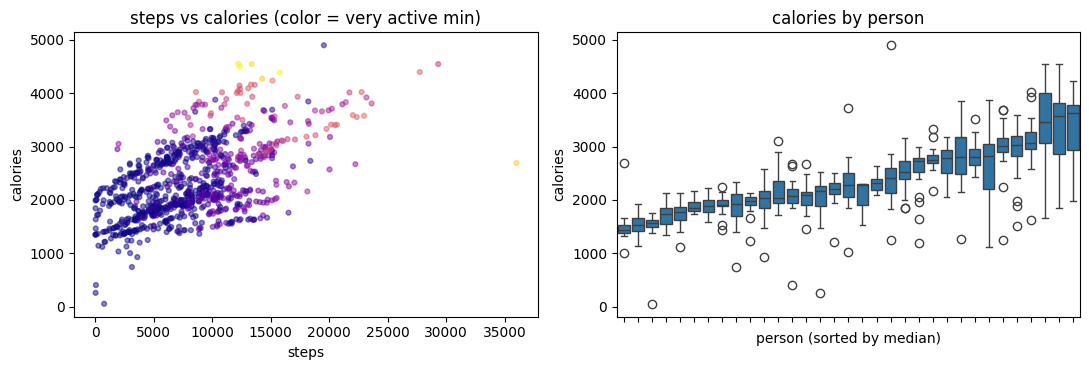

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(df["TotalSteps"], df["calories"], s=12, alpha=0.5, c=df["VeryActiveMinutes"], cmap="plasma")
ax[0].set_xlabel("steps"); ax[0].set_ylabel("calories")
ax[0].set_title("steps vs calories (color = very active min)")
order = df.groupby("Id")["calories"].median().sort_values().index
sns.boxplot(data=df, x="Id", y="calories", order=order, ax=ax[1])
ax[1].set_xticklabels([]); ax[1].set_xlabel("person (sorted by median)")
ax[1].set_title("calories by person")
plt.tight_layout(); plt.savefig(ART / "eda.png", dpi=120); plt.show()

## models

Two evaluations. A random 80/20 split of days lets the same person's other days sit in training, which is how most notebooks on this data report it. A split by person (GroupKFold, 5 folds) asks the harder question: how well does the model do for someone it has never seen?

In [4]:
from sklearn.model_selection import GroupKFold, cross_val_predict
features = ["TotalSteps", "TotalDistance", "VeryActiveMinutes", "FairlyActiveMinutes",
            "LightlyActiveMinutes", "SedentaryMinutes", "VeryActiveDistance", "LightActiveDistance"]
X = df[features].values
y = df["calories"].values
groups = df["Id"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

rows = []
for name, make in [
    ("LinReg", lambda: LinearRegression()),
    ("RF",     lambda: RandomForestRegressor(n_estimators=200, random_state=123, n_jobs=2)),
    ("GBR",    lambda: GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=123)),
]:
    m = make().fit(X_train, y_train)
    pred = m.predict(X_test)
    pred_g = cross_val_predict(make(), X, y, groups=groups, cv=GroupKFold(n_splits=5))
    rows.append({"model": name,
                 "random split MAE": round(mean_absolute_error(y_test, pred), 1),
                 "random split R2": round(r2_score(y_test, pred), 3),
                 "by-person MAE": round(mean_absolute_error(y, pred_g), 1),
                 "by-person R2": round(r2_score(y, pred_g), 3)})
pd.DataFrame(rows).set_index("model")

,random split MAE,random split R2,by-person MAE,by-person R2
model,,,,
LinReg,291.7,0.743,308.2,0.664
RF,333.9,0.671,405.8,0.482
GBR,328.7,0.684,382.5,0.519


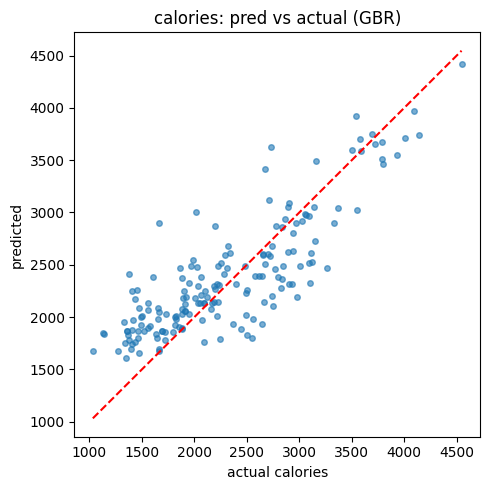

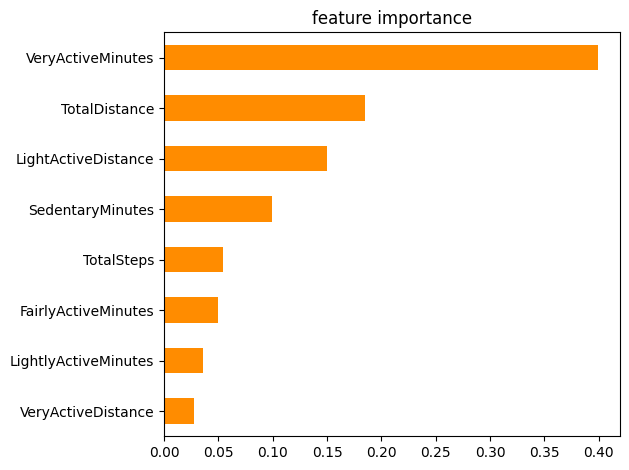

In [5]:
# pred-vs-actual for GBR on the random split
gbr = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=123)
gbr.fit(X_train, y_train)
pred = gbr.predict(X_test)

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, s=16, alpha=0.6)
lo, hi = y_test.min(), y_test.max()
plt.plot([lo, hi], [lo, hi], "r--")
plt.xlabel("actual calories"); plt.ylabel("predicted")
plt.title("calories: pred vs actual (GBR)")
plt.tight_layout(); plt.savefig(ART / "pred_vs_actual.png", dpi=120); plt.show()

fi = pd.Series(gbr.feature_importances_, index=features).sort_values()
fi.plot(kind="barh", color="darkorange")
plt.title("feature importance"); plt.tight_layout()
plt.savefig(ART / "fi.png", dpi=120); plt.show()


## caveats

On 863 real person-days, plain linear regression is the best of the three: MAE about 292 calories and R² 0.74 on a random split of days. The tree models do worse (R² 0.67-0.68), which is a hint that with this little data the relationship is close to additive and the trees mostly fit noise.

The by-person split is the more honest number. When the model has never seen the person, every model gets worse (linear regression R² 0.66, random forest 0.48), because so much of the target is each person's resting burn, set by body size, age and sex, which this file doesn't have. The box plot of calories by person shows the same thing: people sit at very different baselines.

In the gradient boosting model, very-active minutes carry the most weight (0.40 of the importance), then total distance and light-activity distance. That matches intuition: hard exercise is what moves daily calories, while total steps add little once distance is known.

Other limits: 33 people, one month, self-selected MTurk respondents, and the target is Fitbit's own estimate rather than a measured value. Adding the weight log and heart-rate files from the same export (for the people who have them) would be the obvious next step.